# Clearing the Italian day-ahead market with a uniform purchase price (PUN)

**Results for 4 May 2010, reproduced with the MILP of Savelli et al. (2017)**

This notebook runs the market-clearing model of

> I. Savelli, A. Giannitrapani, S. Paoletti, A. Vicino, *An Optimization Model for the
> Electricity Market Clearing Problem with Uniform Purchase Price and Zonal Selling
> Prices*, IEEE Transactions on Power Systems, 2017,

on the real orders of the Italian day-ahead market (MGP) of **4 May 2010**, and compares
the prices it computes with the prices published by the market operator GME.

**Outline**

1. The problem and the model, in brief
2. The data
3. Clearing all 24 hours
4. PUN: model vs. GME
5. Zonal prices and market splits
6. One hour in detail (hour 9)
7. Computational effort
8. How to reproduce

The notebook is saved with its outputs, so it can be read on GitHub without running
anything. The full-day results are cached in `results/20100504_hourly.csv`; running the
notebook only re-solves the day if that file is missing (≈ 7 min with 12 parallel workers).

## 1. The problem and the model, in brief

**Market rules.** Producers submit *offers* (quantity, minimum price) and consumers submit
*bids* (quantity, maximum price) in one of several market **zones**. Transmission
capacity between zones is limited. If a link is congested the zones on either side get
different prices — a **market split**.

* **Producers** in zone $i$ are paid the **zonal price** $\zeta_i$.
* **Consumers** in the six Italian zones (NORD, CNOR, CSUD, SUD, SICI, SARD) — except
  pumping units — all pay one national price, the **PUN** $\pi$
  (*Prezzo Unico Nazionale*, uniform purchase price). It is the average of the zonal
  prices, weighted by the PUN demand accepted in each zone (eq. 1 of the paper):

$$
\pi \;=\; \frac{\sum_{i \in \mathcal Z^\pi} \sum_{k \in \mathcal K^\pi_i} d_k\, \zeta_i}
              {\sum_{k \in \mathcal K^\pi} d_k}.
$$

**Why this is hard.** Without the PUN, clearing is a linear program: maximise social
welfare subject to zonal energy balance and line limits. The zonal prices $\zeta_i$ are
the *dual variables* of the balance constraints. With the PUN, a consumer bid is accepted
by comparing its price with $\pi$ (not with $\zeta_i$). But $\pi$ depends on the
$\zeta_i$, and those depend on which bids are accepted. The prices and the accepted
quantities are determined by each other.

**How the model resolves it** (Section II of the paper):

1. **Bilevel model.** The *upper level* chooses $\pi$ and, for every PUN bid $k$, binaries
   $u^g_k$ (*in the money*: $p^d_k > \pi$, fully accepted) and $u^e_k$
   (*at the money*: $p^d_k = \pi$, possibly partially accepted). The *lower level* is the
   ordinary welfare-maximising LP, whose duals give the $\zeta_i$.
2. **Single level.** The lower-level LP is replaced by its optimality conditions:
   primal feasibility, dual feasibility and **strong duality** (primal = dual objective).
3. **MILP.** The result contains products of binaries and continuous variables
   (e.g. $u^g_k\,\pi$, $u^g_k\,\zeta_i$). They are linearised with **big-M constraints,
   $M = 3000$ €/MWh** (the Italian price cap). The quantity of at-the-money demand in the
   PUN definition is written with a **binary expansion** ($B = 24$ bits, $c = 3$
   decimals, i.e. kWh resolution).

The code ([`src/pun_clearing/model/pun_model.py`](../src/pun_clearing/model/pun_model.py))
labels each constraint with its equation number in Appendix A of the paper. Because
there are no block orders, the 24 hours are independent and solved as 24 separate MILPs
with the open-source solver **HiGHS**.

In [1]:
import logging
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from pyomo.environ import Var, Constraint, value

from pun_clearing.conf import options
from pun_clearing.dataio.gme_importer import GMEImporter
from pun_clearing.model.pun_model import build_model, extract_solution, solve_model
from pun_clearing.run_hourly import solve_hours

logging.disable(logging.WARNING)
pd.set_option("display.precision", 6)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR, RESULTS_DIR = ROOT / "data", ROOT / "results"
DATE = "20100504"
PUN_ZONES = list(options.PUN_ZONES)

# Chart style: thin marks, recessive axes and grid
BLUE, GREY, ORANGE = "#2a78d6", "#52514e", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": GREY,
    "xtick.color": GREY, "ytick.color": GREY,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])

## 2. The data

GME publishes, for every day, all orders submitted to the market
(`MGPOffertePubbliche`), the transmission limits between zones (`MGPLimitiTransito`)
and the resulting prices (`MGPPrezzi`). The importer keeps only valid orders and
classifies demand bids as **PUN bids** (consumers in the six Italian zones, who pay
$\pi$) or **non-PUN bids** (pumping units and foreign zones, who pay $\zeta_i$).
Bids without a price limit (price 0 in the GME files) are given the cap of 3000 €/MWh:
they buy at any price.

In [2]:
importer = GMEImporter(path=str(DATA_DIR), date=DATE)
hourly_data = importer.get_hourly_data()
real_prices = importer.get_real_prices()

ZONE_TYPES = {
    **{z: "Italian zone (PUN)" for z in PUN_ZONES},
    **{z: "foreign zone" for z in ["AUST", "CORS", "COAC", "FRAN", "GREC", "SLOV", "SVIZ"]},
    **{z: "limited production pole" for z in ["BRNN", "FOGN", "MFTV", "PRGP", "ROSN"]},
}
zones = pd.DataFrame(
    [(z.name, ZONE_TYPES.get(z.name, "?")) for z in hourly_data[1].zones.values()],
    columns=["zone", "type"]).sort_values(["type", "zone"])
print(f"{len(zones)} zones, {len(hourly_data[1].lines)} interconnections")
zones.groupby("type")["zone"].apply(", ".join).to_frame("zones")

18 zones, 18 interconnections


,zones
type,
Italian zone (PUN),"CNOR, CSUD, NORD, SARD, SICI, SUD"
foreign zone,"AUST, COAC, CORS, FRAN, GREC, SLOV, SVIZ"
limited production pole,"BRNN, FOGN, MFTV, PRGP, ROSN"


In [3]:
orders = pd.DataFrame([
    {"hour": h,
     "supply offers": len(d.supply_bids),
     "PUN bids": len(d.pun_bids),
     "  of which without price limit": sum(b.price >= options.MAX_PRICE for b in d.pun_bids),
     "non-PUN bids": len(d.demand_bids)}
    for h, d in hourly_data.items()]).set_index("hour")
print("Orders per hour (total over the day in the last row)")
pd.concat([orders.head(4), orders.tail(2), orders.sum().to_frame("day total").T])

Orders per hour (total over the day in the last row)


,supply offers,PUN bids,of which without price limit,non-PUN bids
1,1207,441,433,41
2,1199,440,432,50
3,1189,437,429,48
4,1188,440,428,48
23,1273,441,429,36
24,1239,434,426,37
day total,30802,10560,10334,972


Most PUN demand is **price-independent**: in every hour, all but 8–14 of the
≈ 440 PUN bids have no price limit. The model fixes those bids as fully accepted
(paper, Section III), so only the few priced PUN bids get binary variables.

## 3. Clearing all 24 hours

Each hour is solved as its own MILP. Results are cached in `results/20100504_hourly.csv`;
delete that file to recompute (≈ 7 minutes with 12 parallel workers, each HiGHS solve on
one thread).

In [4]:
RESULTS_FILE = RESULTS_DIR / f"{DATE}_hourly.csv"


def classify(bid):
    return "ITM" if bid.acceptance > 1 - 1e-6 else "ATM" if bid.acceptance > 1e-6 else "OTM"


def hour_row(data, elapsed):
    real = real_prices[data.period]
    names = {z.zone_id: z.name for z in data.zones.values()}
    row = {"hour": data.period, "pun_model": data.pun_price, "pun_gme": real["PUN"]}
    for zone_id, price in data.zonal_prices.items():
        if names[zone_id] in PUN_ZONES:
            row[f"{names[zone_id]}_model"] = price
            row[f"{names[zone_id]}_gme"] = real[names[zone_id]]
    classes = Counter(classify(b) for b in data.pun_bids)
    row.update({
        "pun_demand_mwh": sum(b.acceptance * b.volume for b in data.pun_bids),
        "itm_bids": classes["ITM"], "atm_bids": classes["ATM"], "otm_bids": classes["OTM"],
        "welfare_eur": data.social_welfare, "solve_time_s": elapsed,
        "solver_status": data.solver_status,
    })
    return row


if RESULTS_FILE.exists():
    day = pd.read_csv(RESULTS_FILE, index_col="hour")
    print(f"Loaded cached results from {RESULTS_FILE.relative_to(ROOT)}")
else:
    t0 = time.perf_counter()
    solved = solve_hours(hourly_data, sorted(hourly_data), "appsi_highs", verbose=False, jobs=12)
    day = pd.DataFrame([hour_row(d, t) for d, t in solved.values()]).set_index("hour").sort_index()
    RESULTS_DIR.mkdir(exist_ok=True)
    day.to_csv(RESULTS_FILE)
    print(f"Solved {len(day)} hours in {time.perf_counter() - t0:.0f} s (wall clock)")

print("Solver status per hour:", dict(Counter(day["solver_status"])))

Loaded cached results from results\20100504_hourly.csv
Solver status per hour: {'optimal': 24}


## 4. PUN: model vs. GME

Hours where the model PUN matches GME (|diff| < 1e-5 €/MWh): 24 / 24
Largest PUN difference:          4.45e-07 €/MWh
Largest zonal-price difference:  1.08e-09 €/MWh (GME publishes zonal prices with 2 decimals)


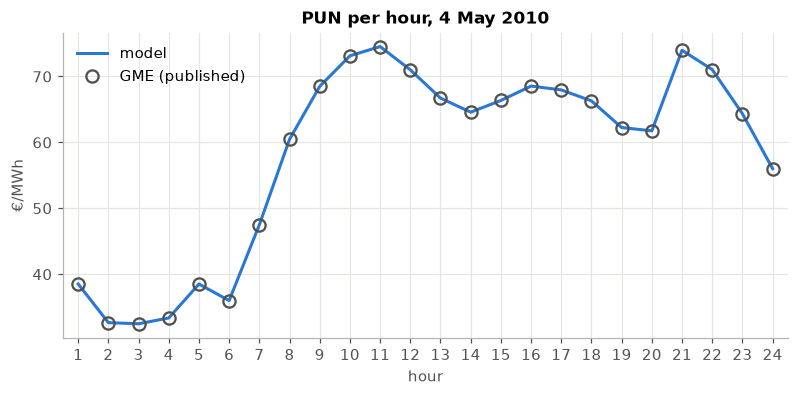

hour,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
pun_model,38.52,32.65,32.48,33.36,38.51,36.0,47.5,60.463068,68.498829,73.130026,...,66.35569,68.543706,67.958972,66.299237,62.250964,61.75337,73.973516,71.045257,64.348253,56.011383
pun_gme,38.52,32.65,32.48,33.36,38.51,36.0,47.5,60.463068,68.498829,73.130026,...,66.35569,68.543706,67.958972,66.299237,62.250964,61.75337,73.973516,71.045257,64.348253,56.011383
pun_diff,0.00,-0.00,0.00,0.00,0.00,0.0,0.0,-0.000000,-0.000000,0.000000,...,0.00000,-0.000000,-0.000000,-0.000000,-0.000000,-0.00000,-0.000000,-0.000000,-0.000000,0.000000


In [5]:
day["pun_diff"] = day["pun_model"] - day["pun_gme"]
zone_diff = pd.concat([day[f"{z}_model"] - day[f"{z}_gme"] for z in PUN_ZONES], axis=1)

print(f"Hours where the model PUN matches GME (|diff| < 1e-5 €/MWh): "
      f"{(day['pun_diff'].abs() < 1e-5).sum()} / {len(day)}")
print(f"Largest PUN difference:          {day['pun_diff'].abs().max():.2e} €/MWh")
print(f"Largest zonal-price difference:  {zone_diff.abs().max().max():.2e} €/MWh "
      f"(GME publishes zonal prices with 2 decimals)")

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(day.index, day["pun_model"], color=BLUE, lw=2, label="model")
ax.plot(day.index, day["pun_gme"], ls="none", marker="o", ms=8, mfc="none",
        mec=GREY, mew=1.5, label="GME (published)")
ax.set(title="PUN per hour, 4 May 2010", xlabel="hour", ylabel="€/MWh",
       xticks=range(1, 25), xlim=(0.5, 24.5))
ax.legend(loc="upper left")
plt.show()

day[["pun_model", "pun_gme", "pun_diff"]].round(6).T

The model reproduces the published PUN in every hour; the differences are at the level
of the solver's numerical tolerance (≈ 10⁻⁷ €/MWh), far below the 6 decimals GME publishes.

## 5. Zonal prices and market splits

Each cell is the zonal price computed by the model. Hours where all six zones share one
price have no market split; otherwise congested interconnections separate the zones.

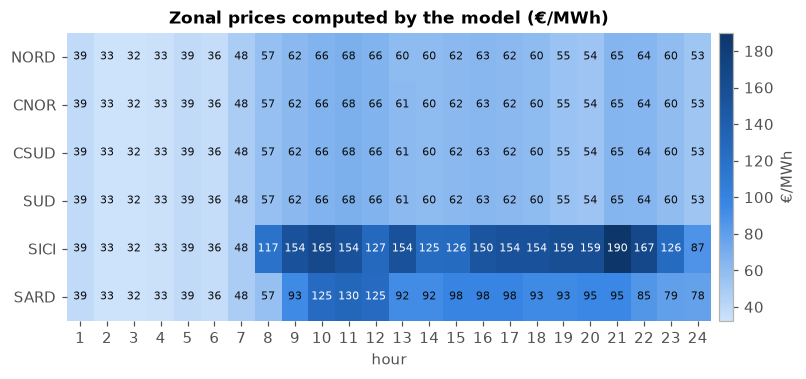

Market split in 17 of 24 hours (hours 8–24).
Number of distinct price areas per hour:


,hours
price areas,
1,7
2,1
3,14
4,2


In [6]:
zonal = day[[f"{z}_model" for z in PUN_ZONES]].rename(columns=lambda c: c[:-6])
day["price_areas"] = zonal.round(2).nunique(axis=1)

fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(zonal.T.values, aspect="auto", cmap=SEQ_BLUE)
ax.set(title="Zonal prices computed by the model (€/MWh)", xlabel="hour",
       xticks=range(24), xticklabels=zonal.index, yticks=range(6), yticklabels=PUN_ZONES)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
vmin, vmax = zonal.values.min(), zonal.values.max()
for (r, c), v in pd.DataFrame(zonal.T.values).stack().items():
    dark = (v - vmin) / (vmax - vmin) > 0.45
    ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=7,
            color="white" if dark else "#0b0b0b")
fig.colorbar(im, ax=ax, pad=0.01, label="€/MWh")
plt.show()

splits = day.loc[day["price_areas"] > 1]
print(f"Market split in {len(splits)} of 24 hours (hours {splits.index.min()}–{splits.index.max()}).")
print("Number of distinct price areas per hour:")
day["price_areas"].value_counts().sort_index().rename_axis("price areas").to_frame("hours")

In the night (hours 1–7) Italy is one price area. From hour 8 onwards the islands
separate: **Sicily** (SICI) becomes the most expensive zone, often joined by
**Sardinia** (SARD). In hours 13 and 19 the north (NORD) separates as well, so up to four
different prices exist at the same time. Consumers in all six zones still pay one PUN,
which lies between the zonal prices, weighted towards the large mainland zones
where most of the demand is.

In [7]:
split_table = pd.DataFrame({
    z: [f"{m:.2f} / {g:.2f}" for m, g in zip(day[f"{z}_model"], day[f"{z}_gme"])]
    for z in PUN_ZONES}, index=day.index).loc[splits.index]
print("Zonal prices in hours with a market split: model / GME (€/MWh)")
split_table

Zonal prices in hours with a market split: model / GME (€/MWh)


,NORD,CNOR,CSUD,SUD,SICI,SARD
hour,,,,,,
8,56.94 / 56.94,56.94 / 56.94,56.94 / 56.94,56.94 / 56.94,116.78 / 116.78,56.94 / 56.94
9,62.33 / 62.33,62.33 / 62.33,62.33 / 62.33,62.33 / 62.33,154.01 / 154.01,93.01 / 93.01
10,65.73 / 65.73,65.73 / 65.73,65.73 / 65.73,65.73 / 65.73,165.00 / 165.00,125.01 / 125.01
11,67.90 / 67.90,67.90 / 67.90,67.90 / 67.90,67.90 / 67.90,154.01 / 154.01,130.01 / 130.01
12,65.85 / 65.85,65.85 / 65.85,65.85 / 65.85,65.85 / 65.85,127.44 / 127.44,125.01 / 125.01
13,59.98 / 59.98,60.95 / 60.95,60.95 / 60.95,60.95 / 60.95,154.01 / 154.01,92.01 / 92.01
14,60.00 / 60.00,60.00 / 60.00,60.00 / 60.00,60.00 / 60.00,124.63 / 124.63,92.01 / 92.01
15,61.83 / 61.83,61.83 / 61.83,61.83 / 61.83,61.83 / 61.83,125.71 / 125.71,98.01 / 98.01
16,62.83 / 62.83,62.83 / 62.83,62.83 / 62.83,62.83 / 62.83,150.10 / 150.10,98.01 / 98.01


## 6. One hour in detail: hour 9

Hour 9 has three price areas. Here the model is built and solved again (≈ 15 s) to look
inside the solution: the energy balance of each zone, the flows on the interconnections
and the role of the PUN bids.

In [8]:
HOUR = 9
data = hourly_data[HOUR]
model = build_model(data)
t0 = time.perf_counter()
solve_model(model, "appsi_highs")
extract_solution(model, data)
print(f"Hour {HOUR} solved in {time.perf_counter() - t0:.1f} s: PUN = {data.pun_price:.6f} €/MWh "
      f"(GME {real_prices[HOUR]['PUN']:.6f})")

names = {z.zone_id: z.name for z in data.zones.values()}
ids = {n: i for i, n in names.items()}


def executed(bids, zone_id):
    return sum(b.acceptance * b.volume for b in bids if b.zone_id == zone_id)


balance = pd.DataFrame([{
    "zone": z,
    "price ζ (€/MWh)": data.zonal_prices[ids[z]],
    "supply (MWh)": executed(data.supply_bids, ids[z]),
    "PUN demand (MWh)": executed(data.pun_bids, ids[z]),
    "other demand (MWh)": executed(data.demand_bids, ids[z]),
    "net import (MWh)": -sum(value(model.F[ids[z], j]) for j in model.Z),
} for z in PUN_ZONES]).set_index("zone")
balance.round(2)

Hour 9 solved in 17.2 s: PUN = 68.498829 €/MWh (GME 68.498829)


,price ζ (€/MWh),supply (MWh),PUN demand (MWh),other demand (MWh),net import (MWh)
zone,,,,,
NORD,62.33,20081.94,24238.38,0,4156.45
CNOR,62.33,2416.97,4744.63,0,2327.66
CSUD,62.33,3512.22,6100.51,0,2588.29
SUD,62.33,1048.15,2999.15,0,1951.00
SICI,154.01,1444.51,2358.51,0,914.00
SARD,93.01,1356.39,1356.39,0,-0.00


Each zone satisfies *supply + net import = demand*. The mainland zones (NORD to SUD) share
one price. The islands do not: Sicily receives energy from the mainland only through
ROSN → SICI, and Sardinia is linked through CSUD → SARD and SARD → CORS (it passes 50 MWh
on to Corsica, so its net import is 0). All three links are at full capacity (table
below), so no more cheap mainland energy can reach the islands, and their own, more
expensive generation sets their zonal price. The interconnections with flow:

In [9]:
flows = pd.DataFrame([{
    "from": names[i], "to": names[j], "flow (MWh)": value(model.F[i, j]),
    "capacity (MWh)": value(model.Fmax[i, j]),
} for i in model.Z for j in model.Z if value(model.F[i, j]) > 1e-6])
flows["congested"] = (flows["capacity (MWh)"] - flows["flow (MWh)"]).abs() < 1e-3
flows["Δζ to − from"] = [data.zonal_prices[ids[t]] - data.zonal_prices[ids[f]]
                          for f, t in zip(flows["from"], flows["to"])]
flows.sort_values(["congested", "flow (MWh)"], ascending=[False, False]).round(2)

,from,to,flow (MWh),capacity (MWh),congested,Δζ to − from
14,ROSN,SICI,100.00,100.0,True,91.68
6,CSUD,SARD,50.00,50.0,True,30.68
7,SARD,CORS,50.00,50.0,True,0.00
12,SVIZ,NORD,3452.00,10000.0,False,0.00
2,BRNN,SUD,3338.00,5200.0,False,0.00
1,NORD,CNOR,2836.55,3600.0,False,-0.00
9,FRAN,NORD,2404.00,10000.0,False,0.00
3,SUD,CSUD,2129.40,3500.0,False,0.00
8,FOGN,SUD,842.39,2000.0,False,0.00
13,PRGP,SICI,814.00,815.0,False,0.00


On every **uncongested** link the two zones have the same price (Δζ = 0). A price
difference appears only across a **congested** link, and then the flow goes towards the
more expensive zone (ROSN → SICI, CSUD → SARD). A full link does not have to separate
prices (SARD → CORS). This is the duality relation in the model: the dual of the flow
limit is zero unless the limit is binding (paper eqs. 44 and 47).

**PUN bids.** Every PUN bid is either *in the money* (ITM, price above π, fully
accepted), *at the money* (ATM, price = π, partly accepted) or *out of the money*
(OTM, rejected):

In [10]:
bids = pd.DataFrame([{
    "class": classify(b), "no price limit": b.price >= options.MAX_PRICE,
    "volume (MWh)": b.volume, "accepted (MWh)": b.acceptance * b.volume,
} for b in data.pun_bids])
summary = bids.groupby(["class", "no price limit"]).agg(
    bids=("volume (MWh)", "size"), offered_MWh=("volume (MWh)", "sum"),
    accepted_MWh=("accepted (MWh)", "sum"))
print(f"PUN = {data.pun_price:.4f} €/MWh")
summary.round(1)

PUN = 68.4988 €/MWh


bids  offered_MWh  accepted_MWh
class no price limit                                 
ITM   False              2          6.0           6.0
      True             434      41791.6       41791.6
OTM   False              6         26.0           0.0

In [11]:
priced = pd.DataFrame([{"price (€/MWh)": b.price, "zone": names[b.zone_id],
                        "volume (MWh)": b.volume, "class": classify(b)}
                       for b in data.pun_bids if b.price < options.MAX_PRICE])
print("The PUN bids that do have a price limit:")
priced.sort_values("price (€/MWh)", ascending=False).round(3)

The PUN bids that do have a price limit:


,price (€/MWh),zone,volume (MWh),class
0,80.83,CNOR,3.0,ITM
1,72.75,CNOR,3.0,ITM
4,68.00,SARD,5.0,OTM
2,64.67,CNOR,3.0,OTM
5,61.20,SARD,5.0,OTM
3,56.58,CNOR,3.0,OTM
6,54.40,SARD,5.0,OTM
7,47.60,SARD,5.0,OTM


This table shows the effect of the PUN rule. The bid at **64.67 €/MWh in CNOR is
rejected**, although the zonal price of CNOR is only 62.33 €/MWh. Under zonal pricing it
would be accepted. But the consumer would pay the PUN (68.50 €/MWh), which is above its
limit. The PUN, and not the zonal price, decides which PUN bids are accepted, and the
PUN in turn depends on which bids are accepted. That circularity is what the bilevel
model resolves. In this hour no bid is exactly at the money (ATM). Over the whole day there is one ATM
bid, in hour 4, where a bid's price equals the PUN and it is only partly accepted (see the
`atm_bids` column of the results file).

**Checking the PUN definition (eq. 1).** The PUN must equal the zonal prices weighted by
the accepted PUN demand per zone. The MILP enforces this through the linearised
constraint (paper eq. 35); here it is recomputed from the solution:

In [12]:
check = balance[["price ζ (€/MWh)", "PUN demand (MWh)"]].copy()
check["ζ × demand"] = check["price ζ (€/MWh)"] * check["PUN demand (MWh)"]
weighted = check["ζ × demand"].sum() / check["PUN demand (MWh)"].sum()
print(f"Σ ζ_i·d_i / Σ d_i = {weighted:.6f} €/MWh")
print(f"π from the MILP  = {data.pun_price:.6f} €/MWh")
print(f"π published      = {real_prices[HOUR]['PUN']:.6f} €/MWh")
check.round(2)

Σ ζ_i·d_i / Σ d_i = 68.498829 €/MWh
π from the MILP  = 68.498829 €/MWh
π published      = 68.498829 €/MWh


,price ζ (€/MWh),PUN demand (MWh),ζ × demand
zone,,,
NORD,62.33,24238.38,1510778.41
CNOR,62.33,4744.63,295732.60
CSUD,62.33,6100.51,380245.04
SUD,62.33,2999.15,186936.89
SICI,154.01,2358.51,363233.82
SARD,93.01,1356.39,126157.83


**Aggregated offer and bid curves.** For intuition, here are all offers (sorted by
price) and all bids (sorted by price, descending) of hour 9 over the whole market. This
ignores the network: with congestion the clearing is zonal, so the curves only give the
overall picture. Demand is almost vertical because nearly all of it has no price limit.

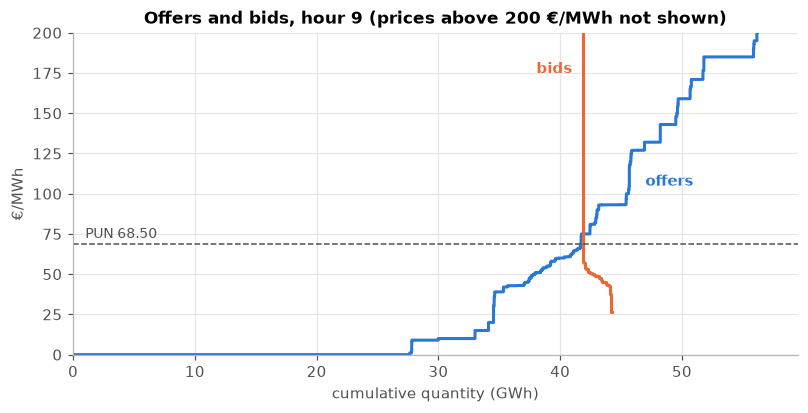

In [13]:
def step_curve(volumes_prices, descending):
    ordered = sorted(volumes_prices, key=lambda vp: vp[1], reverse=descending)
    x, y, total = [0.0], [ordered[0][1]], 0.0
    for v, p in ordered:
        x += [total, total + v]
        y += [p, p]
        total += v
    return x[1:], y[1:]


sx, sy = step_curve([(b.volume, b.price) for b in data.supply_bids], descending=False)
dx, dy = step_curve([(b.volume, b.price) for b in data.pun_bids + data.demand_bids],
                    descending=True)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot([x / 1000 for x in sx], sy, color=BLUE, lw=2)
ax.plot([x / 1000 for x in dx], dy, color=ORANGE, lw=2)
ax.axhline(data.pun_price, color=GREY, lw=1, ls="--")
ax.text(1, data.pun_price + 4, f"PUN {data.pun_price:.2f}", color=GREY, fontsize=9)
ax.text(47, 105, "offers", color=BLUE, fontsize=10, fontweight="bold")
ax.text(41, 175, "bids", color=ORANGE, fontsize=10, fontweight="bold", ha="right")
ax.set(ylim=(0, 200), xlim=(0, max(sx[-1], dx[-1]) / 1000), xlabel="cumulative quantity (GWh)",
       ylabel="€/MWh", title=f"Offers and bids, hour {HOUR} (prices above 200 €/MWh not shown)")
plt.show()

## 7. Computational effort

Every hour is a MILP of roughly 5,800–6,300 variables and 5,500–5,800 constraints.
Only about 160 variables are binary: the merit-order indicators of the few priced PUN bids, plus
24 bits × 6 zones for the binary expansion.

Hour 9: 5833 variables (160 binary), 5788 constraints


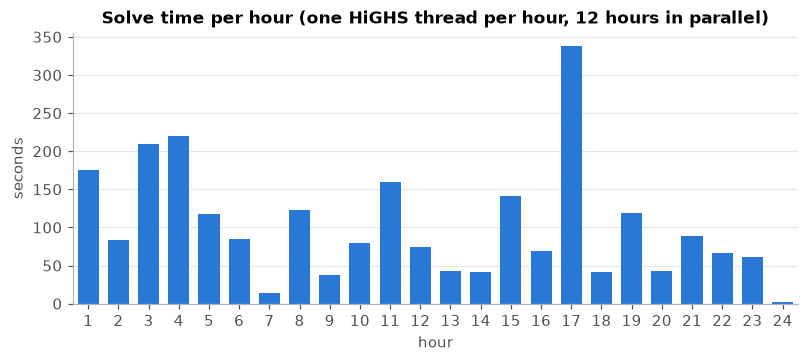

Total: 2434 s of solver time; median 82 s, max 339 s per hour


In [14]:
n_vars = sum(1 for v in model.component_data_objects(Var) if not v.fixed)
n_bin = sum(1 for v in model.component_data_objects(Var) if not v.fixed and v.is_binary())
n_con = sum(1 for _ in model.component_data_objects(Constraint, active=True))
print(f"Hour {HOUR}: {n_vars} variables ({n_bin} binary), {n_con} constraints")

fig, ax = plt.subplots(figsize=(8.5, 3.2))
ax.bar(day.index, day["solve_time_s"], color=BLUE, width=0.7)
ax.set(title="Solve time per hour (one HiGHS thread per hour, 12 hours in parallel)",
       xlabel="hour", ylabel="seconds", xticks=range(1, 25), xlim=(0.5, 24.5))
ax.grid(axis="x", visible=False)
plt.show()
print(f"Total: {day['solve_time_s'].sum():.0f} s of solver time; "
      f"median {day['solve_time_s'].median():.0f} s, max {day['solve_time_s'].max():.0f} s per hour")

Solve times vary a lot between hours and follow no simple pattern (split or not).
In the HiGHS logs we inspected (e.g. hour 2), the optimal solution is found about
halfway through, and the rest of the time goes into **proving** it optimal, because the relative MIP gap is set to 0 (exact
solutions, as in the paper) while the objective (social welfare) is of the order of
10⁸ €. A run with the default number of threads solves a single hour
about 1.5–2× faster than in this parallel run.

## 8. How to reproduce

```bash
python -m venv .venv
.venv\Scripts\Activate.ps1            # Windows;  Linux/macOS: source .venv/bin/activate
pip install -e ".[notebook]"

pun-clearing --path data --date 20100504 --hours 9 --json     # one hour
pun-clearing --path data --date 20100504 --jobs 12 --quiet    # the whole day
```

Or with Docker (HTTP API, one hour per request, documentation at `/docs`):

```bash
docker compose up --build
curl http://localhost:8000/clear/20100504/9
```

To recompute this notebook from scratch, delete `results/20100504_hourly.csv` and run
all cells.